# 01 · Análise exploratória — por que os clientes cancelam?

**Contexto.** Uma operadora de telecom perde cerca de 1 em cada 4 clientes. Adquirir um cliente novo custa bem mais do que manter um atual, então a empresa quer **identificar quem tem risco de cancelar antes que aconteça** e agir com ofertas de retenção.

**Perguntas deste notebook**
1. Os dados estão limpos e confiáveis?
2. Qual o tamanho do problema (em clientes e em receita)?
3. Quais características separam quem fica de quem cancela?

**Dados:** [IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d) — 7.043 clientes, 21 colunas (perfil, serviços contratados, contrato e cobrança).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
from IPython.display import Image, display

from churn.data import clean, load_raw
from churn.features import add_features
from churn import plots

pd.set_option("display.max_columns", 30)
FIG = RAIZ / "reports" / "figures"

## 1. Qualidade dos dados

In [2]:
bruto = load_raw()
print(bruto.shape)
bruto.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Valores nulos "escondidos": TotalCharges vem como texto e tem espaços em branco
em_branco = bruto["TotalCharges"].astype(str).str.strip() == ""
print("TotalCharges em branco:", em_branco.sum())
bruto.loc[em_branco, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

TotalCharges em branco: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Os 11 registros sem `TotalCharges` são **todos clientes com `tenure = 0`**, ou seja, que acabaram de entrar e ainda não pagaram nenhuma fatura. Não é erro aleatório: o valor correto é **0**, então não faz sentido descartar essas linhas nem preencher com a média. Esse tratamento fica em `src/churn/data.py` e é coberto por teste automatizado.

In [4]:
df = add_features(clean(bruto))
print("Nulos após limpeza:", df.isna().sum().sum())
print("IDs duplicados:", df["customerID"].duplicated().sum())
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(1)

Nulos após limpeza: 0
IDs duplicados: 0


,tenure,MonthlyCharges,TotalCharges
count,7043.0,7043.0,7043.0
mean,32.4,64.8,2279.7
std,24.6,30.1,2266.8
min,0.0,18.2,0.0
25%,9.0,35.5,398.6
50%,29.0,70.4,1394.6
75%,55.0,89.8,3786.6
max,72.0,118.8,8684.8


## 2. Tamanho do problema

In [5]:
taxa = df["Churn"].mean()
receita_total = df["MonthlyCharges"].sum()
receita_perdida = df.loc[df["Churn"] == 1, "MonthlyCharges"].sum()
print(f"Taxa de churn: {taxa:.1%} ({df['Churn'].sum():,} clientes)")
print(f"Receita mensal dos clientes que cancelaram: US$ {receita_perdida:,.0f} "
      f"({receita_perdida / receita_total:.1%} da receita mensal)")

Taxa de churn: 26.5% (1,869 clientes)
Receita mensal dos clientes que cancelaram: US$ 139,131 (30.5% da receita mensal)


**26,5% dos clientes cancelaram, mas eles representam 30,5% da receita mensal.** Quem cancela paga, em média, *mais* do que quem fica. O problema é maior em dinheiro do que em número de clientes.

As classes são desbalanceadas (~27% x 73%), por isso a acurácia sozinha engana: um modelo que chuta "ninguém cancela" acerta 73%. Na modelagem uso ROC-AUC, PR-AUC e, principalmente, **lucro**.

## 3. O que diferencia quem cancela?

### 3.1 Tipo de contrato

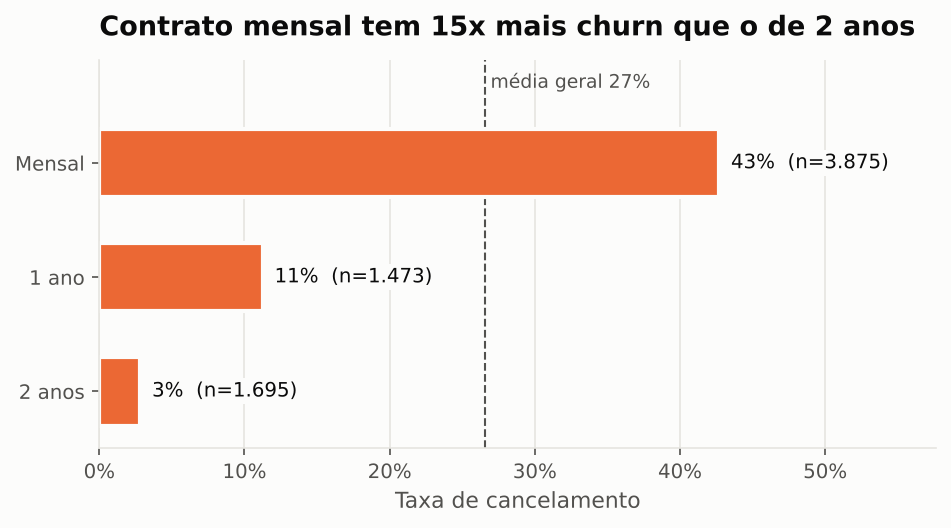

In [6]:
plots.taxa_churn_por(df, "Contract", "Contrato mensal tem 15x mais churn que o de 2 anos",
                     ordem=["Month-to-month", "One year", "Two year"],
                     caminho=FIG / "01_churn_por_contrato.png")
display(Image(FIG / "01_churn_por_contrato.png"))

O contrato é o fator mais forte: **42,7%** de churn no mensal contra **2,8%** no de dois anos. E o mensal é a maioria da base (55%). Migrar clientes para contratos longos é uma alavanca óbvia de retenção.

### 3.2 Tempo de casa

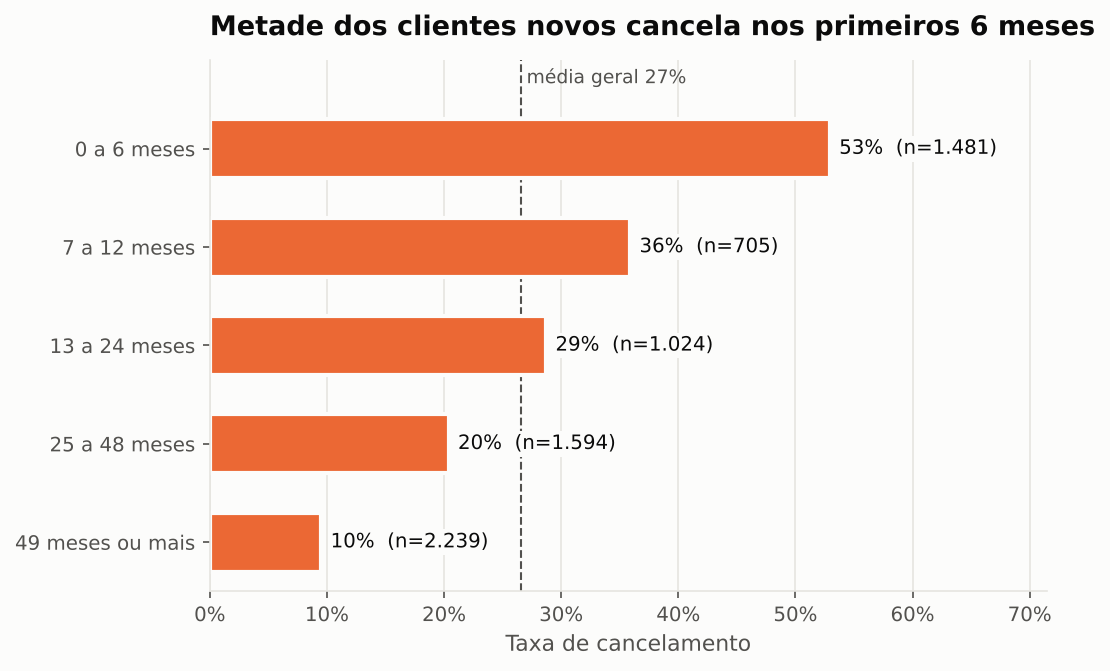

Dos que cancelaram, 55% saíram no 1º ano


In [7]:
plots.taxa_churn_por(df, "faixa_tempo_casa", "Metade dos clientes novos cancela nos primeiros 6 meses",
                     ordem=["0-6m", "7-12m", "13-24m", "25-48m", "49m+"],
                     caminho=FIG / "02_churn_por_tempo_de_casa.png")
display(Image(FIG / "02_churn_por_tempo_de_casa.png"))
print(f"Dos que cancelaram, {(df.loc[df.Churn == 1, 'tenure'] <= 12).mean():.0%} saíram no 1º ano")

O risco despenca com o tempo: **52,9%** de churn nos 6 primeiros meses e **9,5%** após 4 anos. **55% de todos os cancelamentos acontecem no primeiro ano.** O onboarding é o momento crítico.

### 3.3 Forma de pagamento

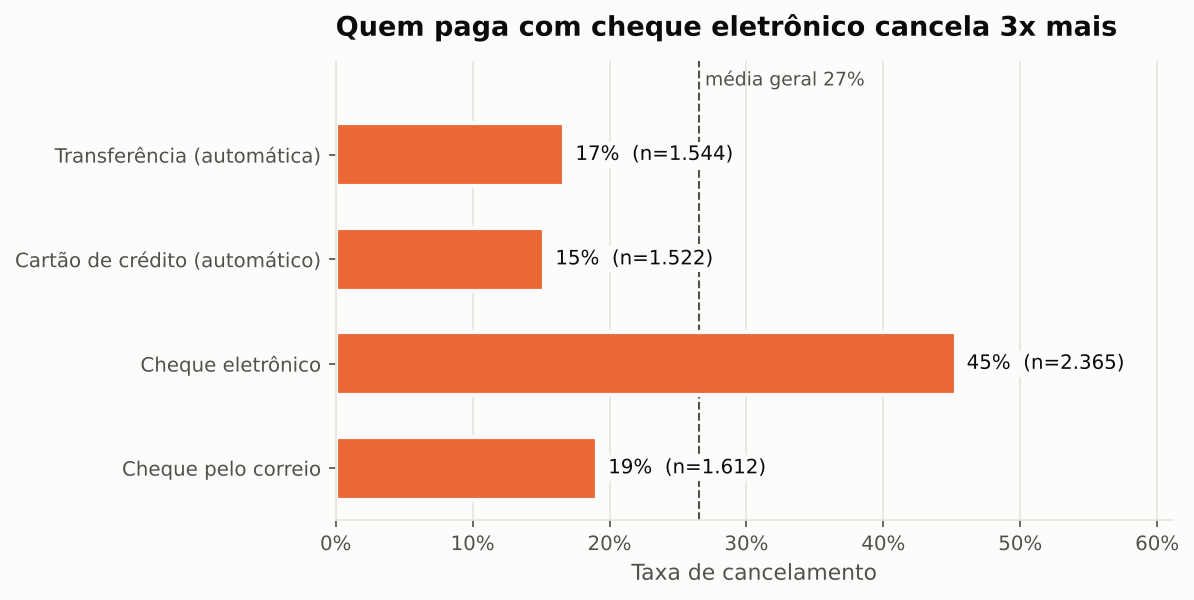

In [8]:
plots.taxa_churn_por(df, "PaymentMethod", "Quem paga com cheque eletrônico cancela 3x mais",
                     caminho=FIG / "03_churn_por_pagamento.png")
display(Image(FIG / "03_churn_por_pagamento.png"))

Quem paga com cheque eletrônico (*electronic check*) cancela **45,3%** das vezes, cerca de 3x mais do que quem usa débito ou cartão automático (~15-17%). Pagamento automático reduz o atrito mensal de "decidir pagar".

### 3.4 Mensalidade

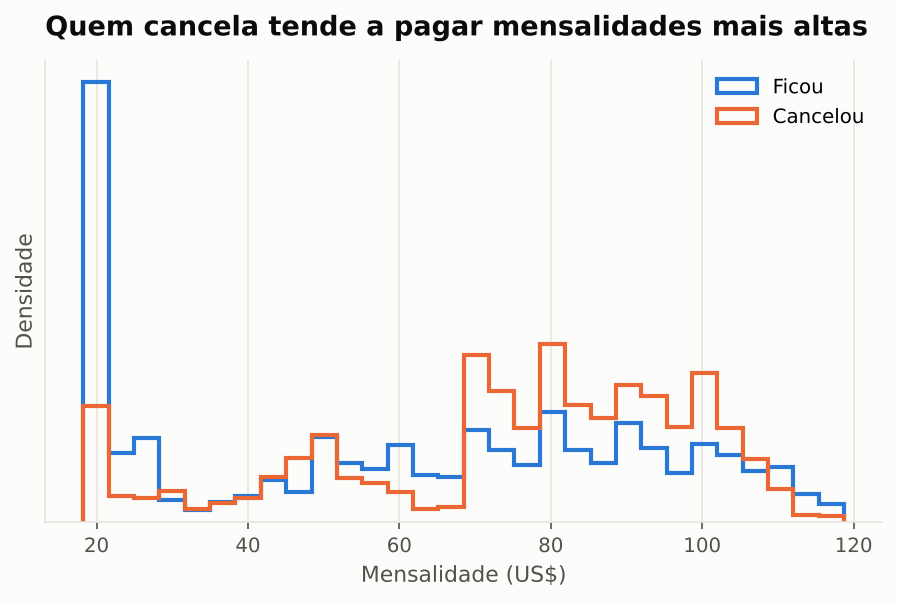

,tenure,MonthlyCharges
Churn,,
Ficou,38.0,64.425
Cancelou,10.0,79.650


In [9]:
plots.distribuicao_por_churn(df, "MonthlyCharges", "Quem cancela tende a pagar mensalidades mais altas",
                             "Mensalidade (US$)", caminho=FIG / "04_mensalidade_por_churn.png")
display(Image(FIG / "04_mensalidade_por_churn.png"))
df.groupby("Churn")[["tenure", "MonthlyCharges"]].median().rename(index={0: "Ficou", 1: "Cancelou"})

A mediana da mensalidade de quem cancela é US$ 79,65 contra US$ 64,43 de quem fica, e há um pico de cancelamentos entre US$ 70 e US$ 105, faixa típica da **fibra óptica**.

### 3.5 Internet, suporte e segurança

In [10]:
tabela = (
    df.groupby(["InternetService", "sem_suporte_protecao"])["Churn"]
      .agg(taxa_churn="mean", clientes="size")
      .round(3)
)
tabela

taxa_churn  clientes
InternetService sem_suporte_protecao                      
DSL             0                          0.140      2002
                1                          0.427       419
Fiber optic     0                          0.337      2248
                1                          0.636       848
No              0                          0.074      1526

- Fibra óptica tem **41,9%** de churn contra 19% no DSL. Pode indicar preço alto ou qualidade abaixo da expectativa — vale cruzar com dados de reclamação.
- Clientes com internet **sem nenhum serviço de segurança, backup, proteção ou suporte** cancelam **56,7%** das vezes. Criei essa variável (`sem_suporte_protecao`) a partir dessa observação.

### 3.6 Combinando os fatores: um segmento crítico

In [11]:
segmento = (df["Contract"] == "Month-to-month") & (df["InternetService"] == "Fiber optic") & (df["tenure"] <= 12)
print(f"Clientes no segmento: {segmento.sum():,} ({segmento.mean():.0%} da base)")
print(f"Churn no segmento: {df.loc[segmento, 'Churn'].mean():.1%}")
print(f"Churn no restante: {df.loc[~segmento, 'Churn'].mean():.1%}")

Clientes no segmento: 916 (13% da base)
Churn no segmento: 70.2%
Churn no restante: 20.0%


**Contrato mensal + fibra + até 12 meses de casa = 70% de churn**, em 13% da base. Uma regra simples já aponta um grupo de altíssimo risco; o modelo de Machine Learning vai além e gera uma probabilidade individual para cada cliente.

### 3.7 O que *não* importa
Gênero praticamente não muda a taxa (26,9% x 26,2%). Bom sinal: não há necessidade de usar uma variável sensível para ter um bom modelo.

## 4. Conclusões da exploração

| Fator | Maior risco | Menor risco |
|---|---|---|
| Contrato | Mensal — 42,7% | 2 anos — 2,8% |
| Tempo de casa | 0-6 meses — 52,9% | 49+ meses — 9,5% |
| Pagamento | Cheque eletrônico — 45,3% | Cartão automático — 15,2% |
| Internet | Fibra — 41,9% | Sem internet — 7,4% |
| Proteção/suporte | Nenhum serviço — 56,7% | Algum serviço — 19,9% |

**Recomendações iniciais para o negócio**
1. Oferecer desconto na migração do plano mensal para o anual nos primeiros meses.
2. Incentivar pagamento automático (ex.: bônus na primeira fatura).
3. Incluir suporte técnico/segurança gratuitos por alguns meses para clientes de fibra.

➡️ Próximo passo: [02_modelagem.ipynb](02_modelagem.ipynb), onde treino modelos para prever o risco individual e calculo o retorno financeiro de uma campanha de retenção.